# Experiment 6: Collisions in Two Dimensions
**Team name:** Science Guys  
**Team members:**  Jacob Rojas, Keith Davis, Treshun Bradley, Brandon Banks  
**Lab dates:** November 9 and November 16, 2026  
**Due:** November 16 at 8:45 p.m.

## Objectives
Test conservation of momentum in two dimensions, compare kinetic energy before and after elastic and inelastic collisions, propagate measurement uncertainties, and evaluate the limitations of the collision model.

Open this notebook from your **team fork** in Colab after **Sync fork -> Update branch**. The supplied measurements are **illustrative examples, not team data**. Run the complete example first, then replace every mass, frequency, path length, angle, and uncertainty with your measurements. Keep your raw measurements and do not type calculated momentum or energy values by hand.

One team notebook is submitted through Scholar. Each student separately submits a private Individual Team Effort Report through Scholar; never commit effort reports to GitHub.

# Apparatus and safety
Collision table with carbon mat, air pucks and compressor, spark timer and foot switch, newsprint recording sheets, balance, ruler, and protractor.

- Inspect the red and black spark-timer cables. Stop and alert the instructor if a cable is damaged, loose, or sparking audibly.
- Keep **both pucks on the table** whenever the foot switch is depressed. Never touch a metal puck while the spark timer is active.
- Use the least force that gives a clean collision. Keep the compressor away from the table and spark timer.
- Do not leave a puck sparking in one place, and do not write on paper while it is on the carbon mat.
- Do not touch the latex air tubes unnecessarily. Keep Velcro clear of the table surface during the inelastic trial.

Read the [printable experiment instructions](https://github.com/brash99/Phys201L/blob/main/Experiment_Instructions/Lab06_Collisions_in_Two_Dimensions.pdf) before collecting data.

# Physical model
For a puck of mass $m$ and velocity $\vec v=(v_x,v_y)$,
$$\vec p=m\vec v,\qquad K=\tfrac12mv^2.$$
If external impulse is negligible during the collision,
$$\vec p_i=\vec p_f,$$
so the $x$ and $y$ components must each agree within uncertainty. Kinetic energy is also conserved for an ideal elastic collision, but not for an inelastic collision.

Choose $+x$ along the incoming path of puck 1. Angles are measured counterclockwise from $+x$: above the axis is positive and below it is negative. Puck 2 begins at rest. For a track segment of length $L$ spanning $N$ spark intervals at frequency $f$,
$$\Delta t=\frac{N}{f},\qquad v=\frac{L}{\Delta t}=\frac{Lf}{N},\qquad v_x=v\cos\theta,\qquad v_y=v\sin\theta.$$
Count **intervals**, not dots: a segment from dot 1 through dot 5 contains four intervals.

For the inelastic collision, measure the two puck paths over the **same post-collision spark interval**. The final center-of-mass velocity is
$$\vec v_{cm}=\frac{m_1\vec v_{1f}+m_2\vec v_{2f}}{m_1+m_2}.$$
Using both outgoing puck velocities retains their translational and orbital motion when calculating final kinetic energy.

# Uncertainty model
The spark-frequency standard uncertainty is 1% of the selected frequency. For a segment measured across several spark intervals,
$$u_v=v\sqrt{\left(\frac{u_L}{L}\right)^2+\left(\frac{u_f}{f}\right)^2}.$$
Angle uncertainty contributes to both velocity components. With $u_\theta$ in radians,
$$u_{v_x}^2=(\cos\theta\,u_v)^2+(v\sin\theta\,u_\theta)^2,$$
$$u_{v_y}^2=(\sin\theta\,u_v)^2+(v\cos\theta\,u_\theta)^2.$$
The notebook propagates independent mass, distance, frequency, and angle uncertainties to momentum and kinetic energy. Shared mass and frequency calibrations create correlations that the simple quadrature totals do not model; interpret the normalized residuals as diagnostics rather than formal hypothesis tests.

Use path segments far enough from the collision that the dots form a straight, evenly spaced track. Measure across several intervals to reduce fractional distance uncertainty. State how you chose $u_L$ and $u_\theta$.

# Experimental workflow
1. Level the air table until a centered puck has no reproducible drift. Put the compressor on the floor and away from the spark timer when possible.
2. Measure both puck masses and the balance uncertainty. Record whether Velcro changes either mass.
3. Place newsprint on the carbon mat. Practice an off-center collision with the spark timer off.
4. Select a spark frequency that produces distinct dots. Record the frequency and use $u_f=0.01f$ unless the instrument specification gives a larger value.
5. Collect one clean elastic collision: puck 1 moves toward stationary puck 2, and both outgoing tracks remain on the paper.
6. On the **underside** of the sheet, label puck identities, collision point, direction of motion, coordinate axes, measured endpoints, dot counts, path lengths, and angles. Photograph or scan the labeled sheet.
7. Add Velcro, reweigh the pucks, and repeat for an inelastic collision. Use synchronized post-collision intervals for the two attached pucks.
8. Enter measurements below, run all cells, check signs and units, and investigate results before leaving the apparatus.

**Team setup, coordinate choice, and measurement method:** REPLACE WITH YOUR DESCRIPTION. Add a labeled diagram or a readable image of each marked recording sheet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

In [2]:
def _positive(**values):
    for name, value in values.items():
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"{name} must be finite and positive")


def segment_velocity(length, u_length, intervals, angle_deg, u_angle_deg, frequency, u_frequency):
    _positive(length=length, u_length=u_length, intervals=intervals,
              u_angle_deg=u_angle_deg, frequency=frequency, u_frequency=u_frequency)
    if int(intervals) != intervals:
        raise ValueError("intervals must be a whole number")
    theta = np.deg2rad(angle_deg)
    u_theta = np.deg2rad(u_angle_deg)
    v = length * frequency / intervals
    u_v = v * np.hypot(u_length / length, u_frequency / frequency)
    vx, vy = v*np.cos(theta), v*np.sin(theta)
    u_vx = np.hypot(np.cos(theta)*u_v, v*np.sin(theta)*u_theta)
    u_vy = np.hypot(np.sin(theta)*u_v, v*np.cos(theta)*u_theta)
    return dict(v=v, u_v=u_v, vx=vx, u_vx=u_vx, vy=vy, u_vy=u_vy)


def puck_row(state, puck, mass, u_mass, velocity):
    v, uv = velocity["v"], velocity["u_v"]
    px, py = mass*velocity["vx"], mass*velocity["vy"]
    u_px = np.hypot(velocity["vx"]*u_mass, mass*velocity["u_vx"])
    u_py = np.hypot(velocity["vy"]*u_mass, mass*velocity["u_vy"])
    K = 0.5*mass*v**2
    u_K = np.hypot(0.5*v**2*u_mass, mass*v*uv)
    return dict(State=state, Puck=puck, **{"m (kg)":mass, "u_m (kg)":u_mass,
        "v_x (m/s)":velocity["vx"], "u_v_x (m/s)":velocity["u_vx"],
        "v_y (m/s)":velocity["vy"], "u_v_y (m/s)":velocity["u_vy"],
        "p_x (kg m/s)":px, "u_p_x":u_px, "p_y (kg m/s)":py, "u_p_y":u_py,
        "K (J)":K, "u_K (J)":u_K})


def analyze_collision(label, m1, u_m1, m2, u_m2, frequency, u_frequency,
                      incoming_1, outgoing_1, outgoing_2):
    _positive(m1=m1, u_m1=u_m1, m2=m2, u_m2=u_m2,
              frequency=frequency, u_frequency=u_frequency)
    zero = dict(v=0.0, u_v=0.0, vx=0.0, u_vx=0.0, vy=0.0, u_vy=0.0)
    velocities = {
        "Puck 1 initial": segment_velocity(**incoming_1, frequency=frequency, u_frequency=u_frequency),
        "Puck 2 initial": zero,
        "Puck 1 final": segment_velocity(**outgoing_1, frequency=frequency, u_frequency=u_frequency),
        "Puck 2 final": segment_velocity(**outgoing_2, frequency=frequency, u_frequency=u_frequency),
    }
    rows = [
        puck_row("Initial", "Puck 1", m1, u_m1, velocities["Puck 1 initial"]),
        puck_row("Initial", "Puck 2", m2, u_m2, velocities["Puck 2 initial"]),
        puck_row("Final", "Puck 1", m1, u_m1, velocities["Puck 1 final"]),
        puck_row("Final", "Puck 2", m2, u_m2, velocities["Puck 2 final"]),
    ]
    detail = pd.DataFrame(rows)
    quantities = [("p_x (kg m/s)", "u_p_x"), ("p_y (kg m/s)", "u_p_y"), ("K (J)", "u_K (J)")]
    totals = {}
    for state in ["Initial", "Final"]:
        subset = detail[detail.State == state]
        totals[state] = {}
        for quantity, uncertainty in quantities:
            totals[state][quantity] = subset[quantity].sum()
            totals[state][uncertainty] = np.sqrt(np.sum(subset[uncertainty]**2))
    summary_rows = []
    for quantity, uncertainty in quantities:
        initial, final = totals["Initial"][quantity], totals["Final"][quantity]
        u_initial, u_final = totals["Initial"][uncertainty], totals["Final"][uncertainty]
        delta = final - initial
        u_delta = np.hypot(u_initial, u_final)
        summary_rows.append({"Quantity":quantity, "Initial":initial, "u_initial":u_initial,
                             "Final":final, "u_final":u_final, "Final - initial":delta,
                             "u_difference":u_delta,
                             "Difference/u_difference":delta/u_delta if u_delta > 0 else np.nan})
    summary = pd.DataFrame(summary_rows)
    p_initial = np.hypot(totals["Initial"]["p_x (kg m/s)"], totals["Initial"]["p_y (kg m/s)"])
    dp = np.hypot(summary.loc[0,"Final - initial"], summary.loc[1,"Final - initial"])
    kinetic_retained = 100*totals["Final"]["K (J)"]/totals["Initial"]["K (J)"]
    vcm_x = totals["Final"]["p_x (kg m/s)"]/(m1+m2)
    vcm_y = totals["Final"]["p_y (kg m/s)"]/(m1+m2)

    print(label)
    print(f"Spark frequency = {frequency:.6g} +/- {u_frequency:.3g} Hz")
    display(detail)
    display(summary)
    print(f"Momentum residual magnitude / initial momentum = {100*dp/p_initial:.3g}%")
    print(f"Kinetic energy retained = {kinetic_retained:.3g}%")
    print(f"Final center-of-mass velocity = ({vcm_x:.6g}, {vcm_y:.6g}) m/s")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    initial_p = [totals["Initial"]["p_x (kg m/s)"], totals["Initial"]["p_y (kg m/s)"]]
    final_p = [totals["Final"]["p_x (kg m/s)"], totals["Final"]["p_y (kg m/s)"]]
    axes[0].quiver([0,0], [0,0], [initial_p[0], final_p[0]], [initial_p[1], final_p[1]],
                   angles="xy", scale_units="xy", scale=1, color=["C0","C1"])
    limit = 1.25*max(abs(np.array(initial_p+final_p)).max(), 1e-6)
    axes[0].set(xlim=(-limit,limit), ylim=(-limit,limit), xlabel="$p_x$ (kg m/s)",
                ylabel="$p_y$ (kg m/s)", title="Total momentum vectors")
    axes[0].axhline(0,color="0.7"); axes[0].axvline(0,color="0.7"); axes[0].grid(alpha=.3)
    axes[0].text(.03,.95,"blue: initial\norange: final",transform=axes[0].transAxes,va="top")
    x=np.arange(2); width=.35
    axes[1].bar(x-width/2, initial_p, width, yerr=[totals["Initial"]["u_p_x"],totals["Initial"]["u_p_y"]],
                capsize=4,label="Initial")
    axes[1].bar(x+width/2, final_p, width, yerr=[totals["Final"]["u_p_x"],totals["Final"]["u_p_y"]],
                capsize=4,label="Final")
    axes[1].set_xticks(x,["$p_x$","$p_y$"]); axes[1].set_ylabel("Momentum (kg m/s)")
    axes[1].set_title("Momentum components"); axes[1].legend(); axes[1].grid(axis="y",alpha=.3)
    kinetic=[totals["Initial"]["K (J)"],totals["Final"]["K (J)"]]
    u_kinetic=[totals["Initial"]["u_K (J)"],totals["Final"]["u_K (J)"]]
    axes[2].bar(["Initial","Final"],kinetic,yerr=u_kinetic,capsize=4,color=["C0","C1"])
    axes[2].set_ylabel("Kinetic energy (J)"); axes[2].set_title("Kinetic energy")
    axes[2].grid(axis="y",alpha=.3)
    fig.suptitle(label); fig.tight_layout(); plt.show()
    return {"detail":detail, "summary":summary, "totals":totals,
            "momentum_residual_percent":100*dp/p_initial,
            "kinetic_retained_percent":kinetic_retained,
            "v_cm_final":(vcm_x,vcm_y)}

# Part I - Elastic collision
Launch puck 1 toward stationary puck 2 so that the collision is off-center and both outgoing paths are measurable. Choose straight pre- and post-collision segments, label the direction of each path, count spark intervals, measure total segment lengths, and record signed angles relative to the incoming $+x$ axis.

Run the example below before replacing it. A negative outgoing angle means the track lies below the $+x$ axis.

In [25]:
# ILLUSTRATIVE EXAMPLE - REPLACE every value with team measurements.
elastic_m1 = 0.54867       # kg
elastic_u_m1 = 0.00005     # kg
elastic_m2 = 0.56449       # kg
elastic_u_m2 = 0.00005     # kg
elastic_frequency = 20.0   # Hz, not seconds per spark
elastic_u_frequency = 0.20 # Hz (1% of frequency)

elastic_incoming_1 = dict(length=0.227, u_length=0.001, intervals=15,
                          angle_deg=0.0, u_angle_deg=0.01)
elastic_outgoing_1 = dict(length=0.227, u_length=0.001, intervals=28,
                          angle_deg=48.0, u_angle_deg=0.5)
elastic_outgoing_2 = dict(length=0.257, u_length=0.001, intervals=26,
                          angle_deg=-31.0, u_angle_deg=0.5)

Elastic collision
Spark frequency = 20 +/- 0.2 Hz


,State,Puck,m (kg),u_m (kg),v_x (m/s),u_v_x (m/s),v_y (m/s),u_v_y (m/s),p_x (kg m/s),u_p_x,p_y (kg m/s),u_p_y,K (J),u_K (J)
0,Initial,Puck 1,0.54867,5e-05,0.302667,0.00330734,0,5.28253e-05,0.166064,0.0018147,0,2.89837e-05,0.025131,0.000549235
1,Initial,Puck 2,0.56449,5e-05,0,0,0,0,0,0,0,0,0,0
2,Final,Puck 1,0.54867,5e-05,0.108495,0.00158469,0.120496,0.00162176,0.0595278,0.00086949,0.0661123,0.000889832,0.00721235,0.000157625
3,Final,Puck 2,0.56449,5e-05,0.169455,0.0020238,-0.101819,0.0018386,0.0956559,0.00114245,-0.0574758,0.00103788,0.0110308,0.00023673


,Quantity,Initial,u_initial,Final,u_final,Final - initial,u_difference,Difference/u_difference
0,p_x (kg m/s),0.166064,0.0018147,0.155184,0.00143569,-0.0108804,0.00231394,-4.70212
1,p_y (kg m/s),0,2.89837e-05,0.00863649,0.00136712,0.00863649,0.00136742,6.31589
2,K (J),0.025131,0.000549235,0.0182431,0.000284406,-0.00688792,0.000618503,-11.1364


Momentum residual magnitude / initial momentum = 8.37%
Kinetic energy retained = 72.6%
Final center-of-mass velocity = (0.139408, 0.00775853) m/s


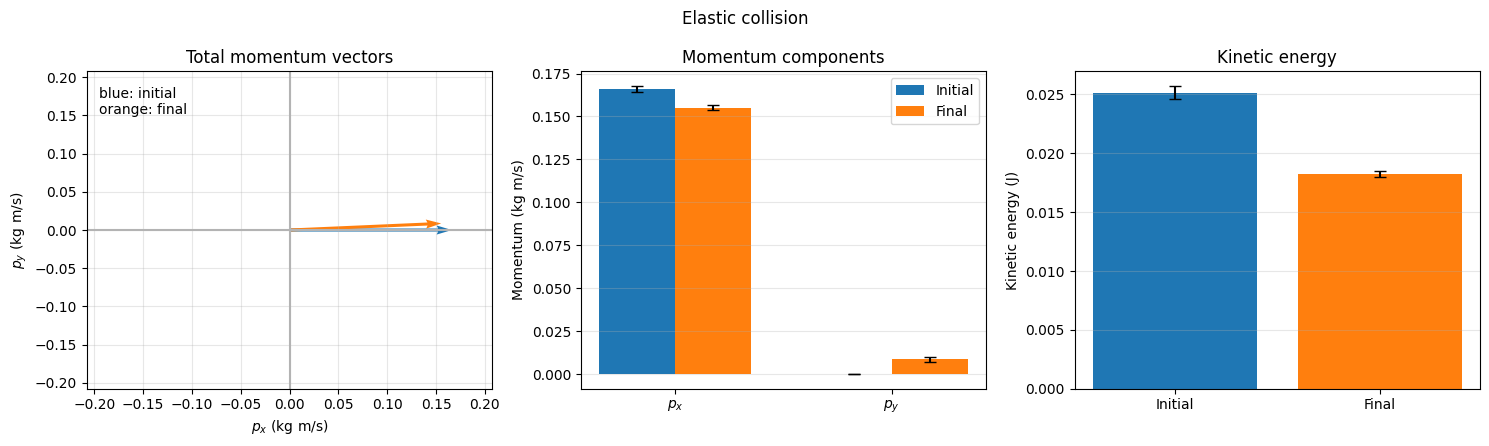

In [26]:
elastic_result = analyze_collision(
    "Elastic collision", elastic_m1, elastic_u_m1, elastic_m2, elastic_u_m2,
    elastic_frequency, elastic_u_frequency,
    elastic_incoming_1, elastic_outgoing_1, elastic_outgoing_2)

## Elastic-collision checkpoint
REPLACE WITH YOUR RESPONSE:

- Do initial and final $p_x$ agree within uncertainty? Quote the difference and its uncertainty.
- Do initial and final $p_y$ agree within uncertainty? Check the **signs** of both outgoing angles before interpreting disagreement.
- What percentage of the initial momentum magnitude remains as the vector residual $|\vec p_f-\vec p_i|$?
- What percentage of kinetic energy was retained? Was this collision actually elastic within uncertainty?
- Identify specific measurement or apparatus effects that could explain the discrepancies. Do not use “human error” as an explanation.

# Part II - Inelastic collision
Wrap the pucks with Velcro without allowing it to drag. Reweigh both pucks. Repeat the collision and measure the incoming path plus both outgoing puck paths. Because the attached pucks may orbit their center of mass, use the **same starting and ending spark indices** for both outgoing measurements. The notebook will calculate the final center-of-mass velocity from their mass-weighted velocities.

In [30]:
# ILLUSTRATIVE EXAMPLE - REPLACE every value with team measurements.
inelastic_m1 = 0.55187       # kg, including Velcro
inelastic_u_m1 = 0.00005     # kg
inelastic_m2 = 0.56735       # kg, including Velcro
inelastic_u_m2 = 0.00005     # kg
inelastic_frequency = 20.0   # Hz
inelastic_u_frequency = 0.20 # Hz (1% of frequency)

inelastic_incoming_1 = dict(length=0.145, u_length=0.001, intervals=8,
                            angle_deg=0.0, u_angle_deg=0.01)
inelastic_outgoing_1 = dict(length=0.151, u_length=0.001, intervals=17,
                            angle_deg=6.0, u_angle_deg=1.0)
inelastic_outgoing_2 = dict(length=0.161, u_length=0.001, intervals=22,
                            angle_deg=-10, u_angle_deg=1.0)

Inelastic collision
Spark frequency = 20 +/- 0.2 Hz


,State,Puck,m (kg),u_m (kg),v_x (m/s),u_v_x (m/s),v_y (m/s),u_v_y (m/s),p_x (kg m/s),u_p_x,p_y (kg m/s),u_p_y,K (J),u_K (J)
0,Initial,Puck 1,0.55187,5e-05,0.3625,0.00440348,0,6.32682e-05,0.200053,0.00243022,0,3.49158e-05,0.0362596,0.000880935
1,Initial,Puck 2,0.56735,5e-05,0,0,0,0,0,0,0,0,0,0
2,Final,Puck 1,0.55187,5e-05,0.176674,0.00214368,0.0185692,0.00309157,0.097501,0.00118307,0.0102478,0.00170615,0.00870809,0.000208892
3,Final,Puck 2,0.56735,5e-05,0.14414,0.00175383,-0.0254158,0.00253345,0.0817779,0.000995064,-0.0144196,0.00143735,0.00607697,0.000143077


,Quantity,Initial,u_initial,Final,u_final,Final - initial,u_difference,Difference/u_difference
0,p_x (kg m/s),0.200053,0.00243022,0.179279,0.0015459,-0.020774,0.00288023,-7.21261
1,p_y (kg m/s),0,3.49158e-05,-0.00417187,0.0022309,-0.00417187,0.00223117,-1.86981
2,K (J),0.0362596,0.000880935,0.0147851,0.000253193,-0.0214745,0.000916599,-23.4285


Momentum residual magnitude / initial momentum = 10.6%
Kinetic energy retained = 40.8%
Final center-of-mass velocity = (0.160182, -0.00372748) m/s


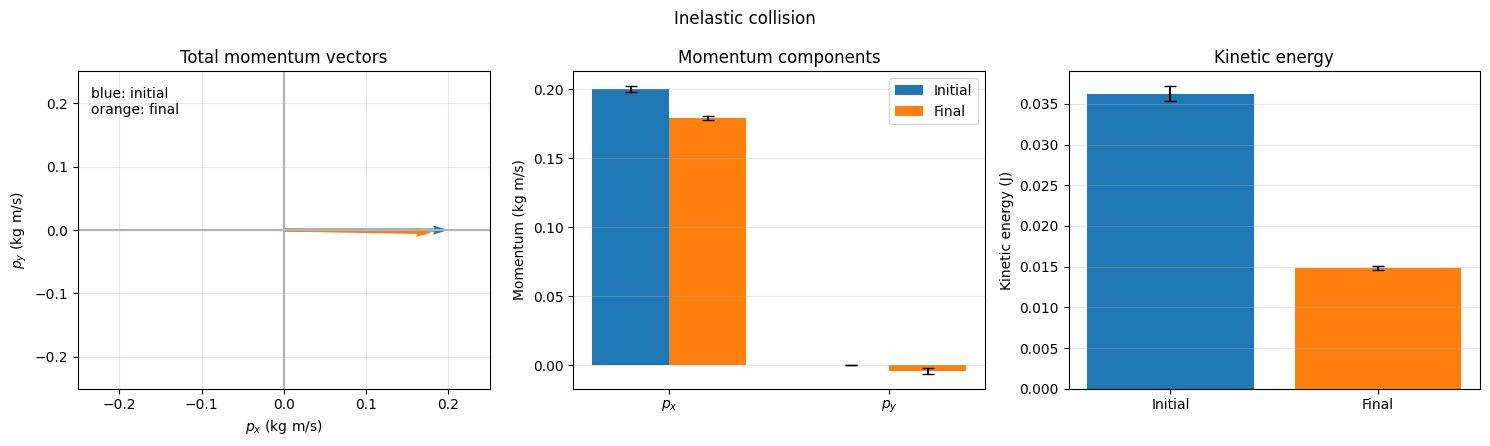

In [31]:
inelastic_result = analyze_collision(
    "Inelastic collision", inelastic_m1, inelastic_u_m1, inelastic_m2, inelastic_u_m2,
    inelastic_frequency, inelastic_u_frequency,
    inelastic_incoming_1, inelastic_outgoing_1, inelastic_outgoing_2)

## Inelastic-collision checkpoint
REPLACE WITH YOUR RESPONSE:

- Compare initial and final $p_x$ and $p_y$ quantitatively, including uncertainty.
- Quote the final center-of-mass velocity and explain why the two puck velocities need not be identical while the joined pair rotates.
- What percentage of kinetic energy was retained? Where did the missing mechanical energy go?
- Compare the momentum residual and kinetic-energy retention with the elastic collision.
- Identify specific limitations of your measurements and apparatus.

# Required worked uncertainty example
Show **one** complete uncertainty calculation using your values. A good choice is one outgoing $p_y$ value because it includes mass, distance, frequency, and angle uncertainty. Define every symbol, substitute numbers with units, and compare your result with the notebook output. You do not need to reproduce every propagated uncertainty.

**Worked calculation:** REPLACE WITH EQUATIONS, NUMERICAL SUBSTITUTION, AND RESULT.

# Written laboratory record

## Introduction and physical model
REPLACE WITH a concise explanation of what you tested, why momentum is expected to be conserved, and why kinetic energy behaves differently for elastic and inelastic collisions. Define the coordinate system and the test you use for agreement within uncertainty.

## Experimental method
REPLACE WITH enough detail for another group to reproduce the work: table leveling, puck masses, spark settings, collision geometry, dot-interval selection, signed-angle convention, length and angle measurement, Velcro configuration, and how synchronized inelastic intervals were selected. Describe changes made after inspecting early results.

## Results and interpretation
REPLACE WITH a connected discussion that cites the generated tables and figures. Address both momentum components, vector residuals, normalized differences, kinetic-energy retention, center-of-mass motion, uncertainty limitations, and concrete sources of non-ideal behavior. Distinguish a model limitation or measurement uncertainty from a mistake.

## Conclusion
REPLACE WITH the main quantitative findings and whether the evidence supports conservation of momentum and the expected energy behavior for each collision.

# Submission checklist
- [ ] Team name, all members, dates, setup description, and labeled recording-sheet images are present.
- [ ] Every illustrative mass, frequency, length, interval count, angle, and uncertainty was replaced.
- [ ] Angles follow the stated sign convention; both inelastic outgoing measurements use synchronized intervals.
- [ ] Notebook runs from top to bottom with no errors and all tables and figures are visible.
- [ ] Both checkpoints, the worked uncertainty example, and all written sections are complete.
- [ ] At least one teammate checked units, signs, significant figures, and the final GitHub rendering.
- [ ] The repository manager saved to the original path and submitted the GitHub notebook URL in Scholar by 8:45 p.m.
- [ ] Each student submitted the private effort report in Scholar, not GitHub.